In [1]:
import pandas as pd

In [2]:
from rdkit import Chem

In [19]:
from pathlib import Path
ROOT = Path.home() / "projects" / "mol-lab"

In [3]:
df = pd.read_csv("../data/aqsoldb.tsv", sep="\t")
df

,Drug_ID,Drug,Y
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065
...,...,...,...
9977,tetracaine,CCCCNc1ccc(C(=O)OCCN(C)C)cc1,-3.010000
9978,tetracycline,CN(C)[C@@H]1C(O)=C(C(N)=O)C(=O)[C@@]2(O)C(O)=C...,-2.930000
9979,thymol,Cc1ccc(C(C)C)c(O)c1,-2.190000
9980,verapamil,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...,-3.980000


In [4]:
df.Y.describe()

count    9982.000000
mean       -2.889909
std         2.368154
min       -13.171900
25%        -4.326325
50%        -2.618173
75%        -1.209735
max         2.137682
Name: Y, dtype: float64

In [5]:
df["mol"] = df.Drug.apply(Chem.MolFromSmiles)

[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not removing hydrogen atom without neighbors
[03:20:51] WARNING: not r

In [6]:
df

,Drug_ID,Drug,Y,mol
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127,<rdkit.Chem.rdchem.Mol object at 0x110da3450>
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767,<rdkit.Chem.rdchem.Mol object at 0x110da3680>
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078,<rdkit.Chem.rdchem.Mol object at 0x110da3920>
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409,<rdkit.Chem.rdchem.Mol object at 0x110da36f0>
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065,<rdkit.Chem.rdchem.Mol object at 0x110da3990>
...,...,...,...,...
9977,tetracaine,CCCCNc1ccc(C(=O)OCCN(C)C)cc1,-3.010000,<rdkit.Chem.rdchem.Mol object at 0x110eee490>
9978,tetracycline,CN(C)[C@@H]1C(O)=C(C(N)=O)C(=O)[C@@]2(O)C(O)=C...,-2.930000,<rdkit.Chem.rdchem.Mol object at 0x110eee500>
9979,thymol,Cc1ccc(C(C)C)c(O)c1,-2.190000,<rdkit.Chem.rdchem.Mol object at 0x110eee570>
9980,verapamil,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...,-3.980000,<rdkit.Chem.rdchem.Mol object at 0x110eee5e0>


In [16]:
df.mol.describe()

count                                              9980
unique                                             9980
top       <rdkit.Chem.rdchem.Mol object at 0x110da3450>
freq                                                  1
Name: mol, dtype: object

In [8]:
m = Chem.MolFromSmiles("O=Cc1ccc(Cl)cc1")
m

In [9]:
m.GetNumAtoms()

9

In [10]:
a = [a.GetSymbol() for a in m.GetAtoms()]
a

['O', 'C', 'C', 'C', 'C', 'C', 'Cl', 'C', 'C']

In [11]:
b = [(b.GetBeginAtomIdx(), b.GetEndAtomIdx(), str(b.GetBondType())) for b in m.GetBonds()]
b

[(0, 1, 'DOUBLE'),
 (1, 2, 'SINGLE'),
 (2, 3, 'AROMATIC'),
 (3, 4, 'AROMATIC'),
 (4, 5, 'AROMATIC'),
 (5, 6, 'SINGLE'),
 (5, 7, 'AROMATIC'),
 (7, 8, 'AROMATIC'),
 (8, 2, 'AROMATIC')]

In [14]:
print(df.mol.isna().sum(), "invalid")

0 invalid


In [13]:
df = df[df.mol.notna()].reset_index(drop=True)

In [17]:
df.mol.apply(lambda m: m.GetNumAtoms()).describe()

count    9980.000000
mean       17.382966
std        12.241598
min         1.000000
25%        11.000000
50%        15.000000
75%        21.000000
max       388.000000
Name: mol, dtype: float64

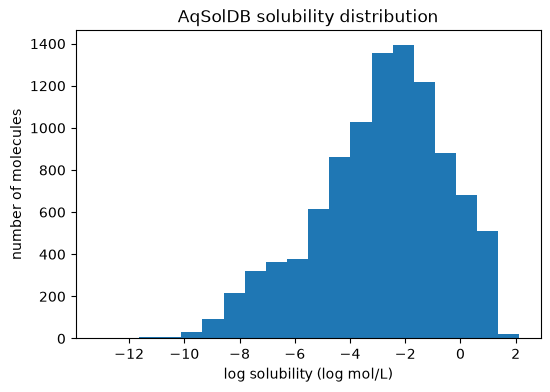

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df.Y, bins=20)
ax.set_xlabel("log solubility (log mol/L)")
ax.set_ylabel("number of molecules")
ax.set_title("AqSolDB solubility distribution")
fig.savefig(ROOT / "notes" / "y_hist.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
print((df.Y < -8).sum())

280


In [24]:
print((df.Y > 0).sum())

1055


In [26]:
sorted_df = df.sort_values("Y")      # lowest Y (least soluble) first
low  = sorted_df.head(4)             # 4 least soluble
high = sorted_df.tail(4)             # 4 most soluble
pick = pd.concat([low, high])        # 8 rows in one table

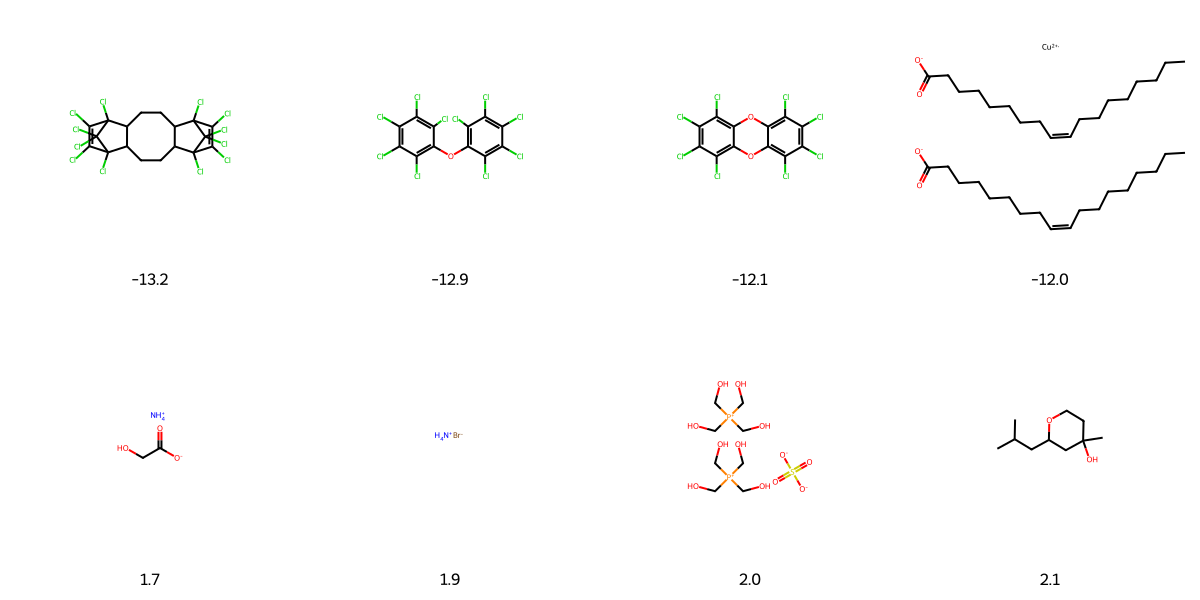

In [27]:
from rdkit.Chem import Draw

img = Draw.MolsToGridImage(
    list(pick.mol),
    molsPerRow=4,
    subImgSize=(300, 300),
    legends=[f"{y:.1f}" for y in pick.Y],
)
img

In [28]:
img.save(ROOT / "notes" / "extremes.png")

In [29]:
from rdkit.Chem import Descriptors
df["logp"] = df.mol.apply(Descriptors.MolLogP)

In [30]:
print(df[["logp", "Y"]].corr())                    # Pearson
print(df[["logp", "Y"]].corr(method="spearman"))   # Spearman

          logp         Y
logp  1.000000 -0.608778
Y    -0.608778  1.000000
          logp         Y
logp  1.000000 -0.739851
Y    -0.739851  1.000000


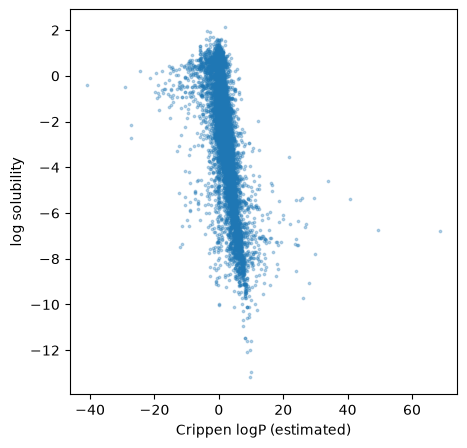

In [31]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df.logp, df.Y, s=3, alpha=0.3)
ax.set_xlabel("Crippen logP (estimated)")
ax.set_ylabel("log solubility")
fig.savefig(ROOT / "notes" / "logp_vs_y.png", dpi=150, bbox_inches="tight")